In [2]:
%cd ..


/home/willraftery/PhD/projects/github/emg-stream


In [3]:
from pathlib import Path
import os
import h5py
import scipy.io
import numpy as np


In [4]:
mat_files = sorted(Path("data/ninapro_db2").rglob("*.mat"))
for fpath in mat_files:
    mat = scipy.io.loadmat(str(fpath))
    print(f'Fname: {fpath.name}, Exercise: {mat["exercise"]}, Subject: {mat["subject"]}')
    restimulus = mat['restimulus'] if 'restimulus' in mat else None
    print(f'  restimulus shape: {restimulus.shape if restimulus is not None else "N/A"}')
    unique_labels = np.unique(restimulus) if restimulus is not None else None
    print(f'Unique labels: {unique_labels if unique_labels is not None else "N/A"}')

Fname: S10_E1_A1.mat, Exercise: [[1]], Subject: [[10]]
  restimulus shape: (1805836, 1)
Unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17]
Fname: S10_E2_A1.mat, Exercise: [[2]], Subject: [[10]]
  restimulus shape: (2547993, 1)
Unique labels: [ 0 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40]
Fname: S10_E3_A1.mat, Exercise: [[3]], Subject: [[10]]
  restimulus shape: (875503, 1)
Unique labels: [ 0 41 42 43 44 45 46 47 48 49]
Fname: S11_E1_A1.mat, Exercise: [[1]], Subject: [[11]]
  restimulus shape: (1803896, 1)
Unique labels: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17]
Fname: S11_E2_A1.mat, Exercise: [[2]], Subject: [[11]]
  restimulus shape: (2545808, 1)
Unique labels: [ 0 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40]
Fname: S11_E3_A1.mat, Exercise: [[3]], Subject: [[11]]
  restimulus shape: (874263, 1)
Unique labels: [ 0 41 42 43 44 45 46 47 48 49]
Fname: S12_E1_A1.mat, Exercise: [[1]], Subject: [[12]]
  res

In [9]:
emg_min, emg_max = 0, 0
force_min, force_max = 0, 0
inclin_min, inclin_max = 0, 0
glove_min, glove_max = 0, 0

force_nan_count = 0
inclin_nan_count = 0
glove_nan_count = 0

mat_files = sorted(Path("data/ninapro_db2").rglob("*.mat"))
total_files = len(mat_files)
for fpath in mat_files:
    mat = scipy.io.loadmat(str(fpath))

    emg = mat['emg'].astype(np.float32)
    emg_min = min(emg_min, emg.min())
    emg_max = max(emg_max, emg.max())

    if 'force' in mat:
        force = mat['force'].astype(np.float32)
        force_min = min(force_min, force.min())
        force_max = max(force_max, force.max())
    else:
        force_nan_count += 1

    if 'inclin' in mat:   
        inclin = mat['inclin'].astype(np.float32)
        inclin_min = min(inclin_min, inclin.min())
        inclin_max = max(inclin_max, inclin.max())
    else:
        inclin_nan_count += 1

    if 'glove' in mat:
        glove = mat['glove'].astype(np.float32)
        glove_min = min(glove_min, glove.min())
        glove_max = max(glove_max, glove.max())
    else:
        glove_nan_count += 1

print(f'EMG min: {emg_min}, EMG max: {emg_max}')
print(f'Force min: {force_min}, Force max: {force_max}')
print(f'Inclin min: {inclin_min}, Inclin max: {inclin_max}')
print(f'Glove min: {glove_min}, Glove max: {glove_max}')
print(f'Total files: {total_files}')
print(f'Files missing force data: {force_nan_count}')
print(f'Files missing inclin data: {inclin_nan_count}')
print(f'Files missing glove data: {glove_nan_count}')

EMG min: -0.011277434416115284, EMG max: 0.01201413944363594
Force min: -15.814221382141113, Force max: 65.72172546386719
Inclin min: -60.36376953125, Inclin max: 60.547000885009766
Glove min: -1619.9971923828125, Glove max: 1344.70361328125
Total files: 120
Files missing force data: 80
Files missing inclin data: 40
Files missing glove data: 40


In [13]:
path = "data/ninapro_db2/S2_E2_A1.mat"

mat = scipy.io.loadmat(path)
print(mat.keys())

print(f"EMG shape: {mat['emg'].shape}")  # (number of samples, number of electrodes)
print(f"ACC shape: {mat['acc'].shape}")
print(f"Glove shape: {mat['glove'].shape}")
print(f"Inclin shape: {mat['inclin'].shape}")
print(f"Stimulus shape: {mat['stimulus'].shape}")  # (number of samples, 1)
print(f"Refined Stimulus shape: {mat['restimulus'].shape}")  # (number of samples, 1)
print(f"Subject: {mat['subject']}")
print(f"Exercise: {mat['exercise']}")
print(f"Repetition shape: {mat['repetition'].shape}")
print(f"Refined Repetition shape: {mat['rerepetition'].shape}")  # (number of samples, 1)

emg = mat['emg']  # (number of samples, number of electrodes)
print(np.max(np.abs(emg)))  # Check the max absolute value for normalization

dict_keys(['__header__', '__version__', '__globals__', 'emg', 'acc', 'stimulus', 'glove', 'inclin', 'subject', 'exercise', 'repetition', 'restimulus', 'rerepetition'])
EMG shape: (2550528, 12)
ACC shape: (2550528, 36)
Glove shape: (2550528, 22)
Inclin shape: (2550528, 2)
Stimulus shape: (2550528, 1)
Refined Stimulus shape: (2550528, 1)
Subject: [[2]]
Exercise: [[2]]
Repetition shape: (2550528, 1)
Refined Repetition shape: (2550528, 1)
0.0020718523


In [10]:
stimulus = mat['stimulus']
repetition = mat['repetition']

print(np.unique(stimulus))  # Unique gesture labels
print(np.unique(repetition))  # Unique repetition numbers

[ 0 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40]
[0 1 2 3 4 5 6]


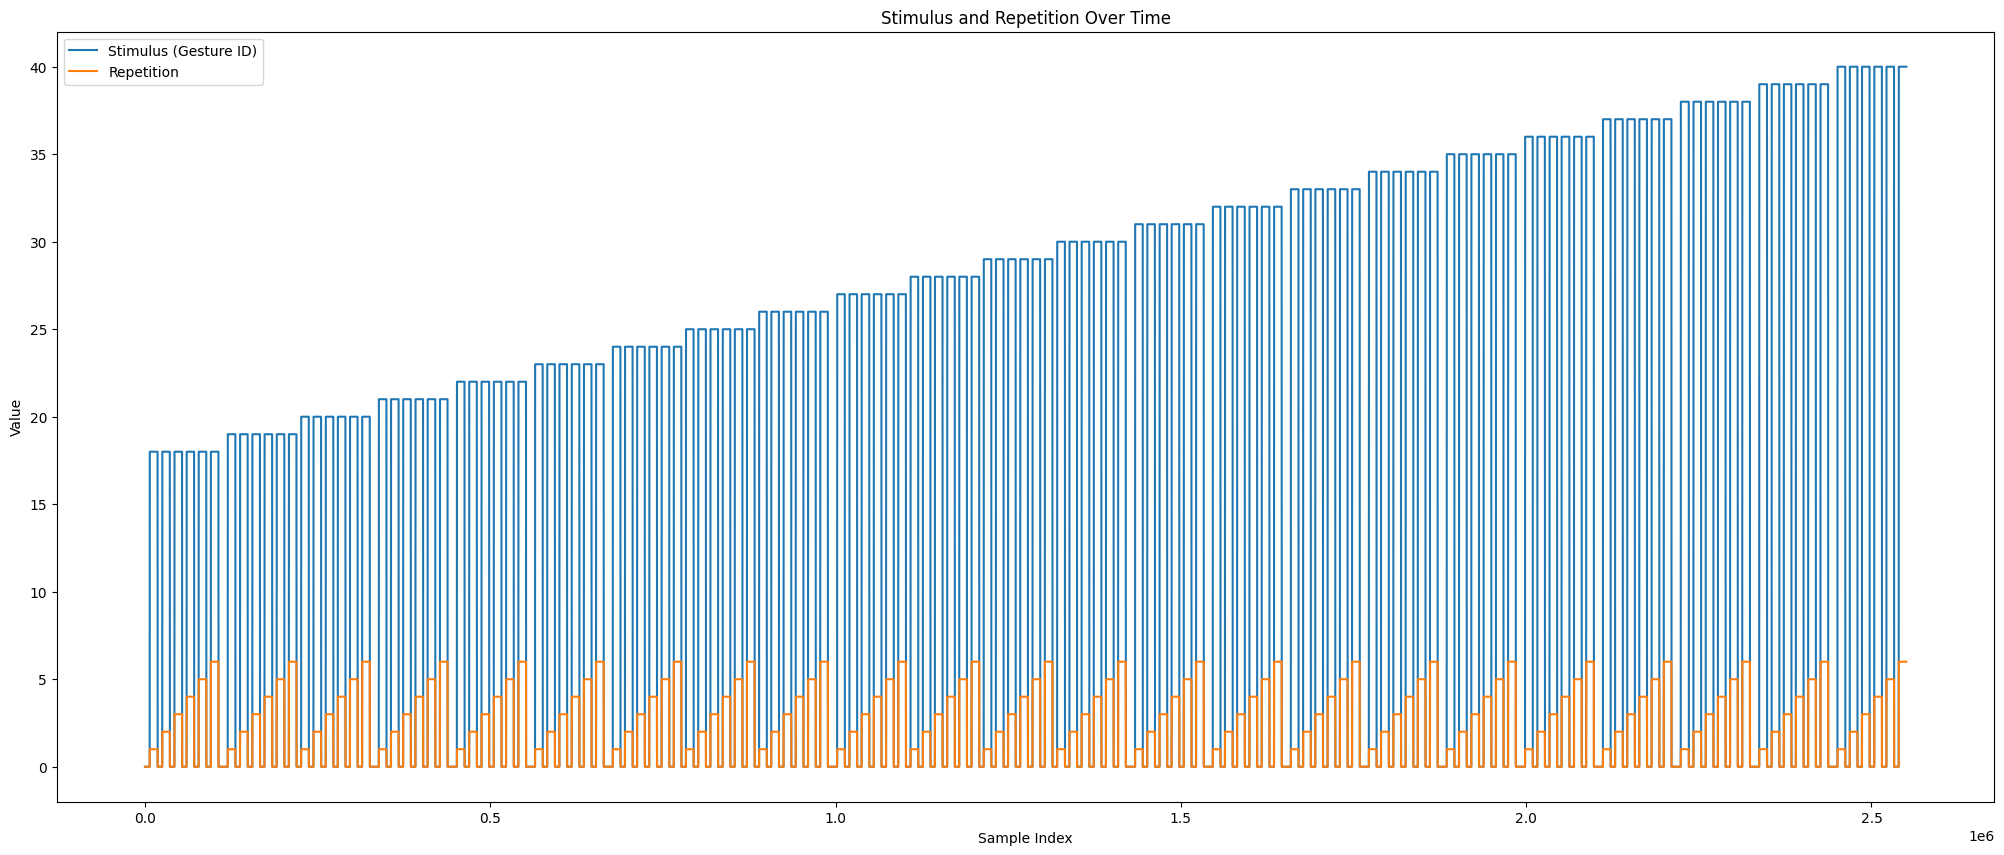

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(25, 10))
plt.plot(stimulus, label='Stimulus (Gesture ID)')
plt.plot(repetition, label='Repetition')
plt.xlabel('Sample Index')
plt.ylabel('Value')
plt.title('Stimulus and Repetition Over Time')
plt.legend()
plt.show()

[ 0 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40]
[0 1 2 3 4 5 6]


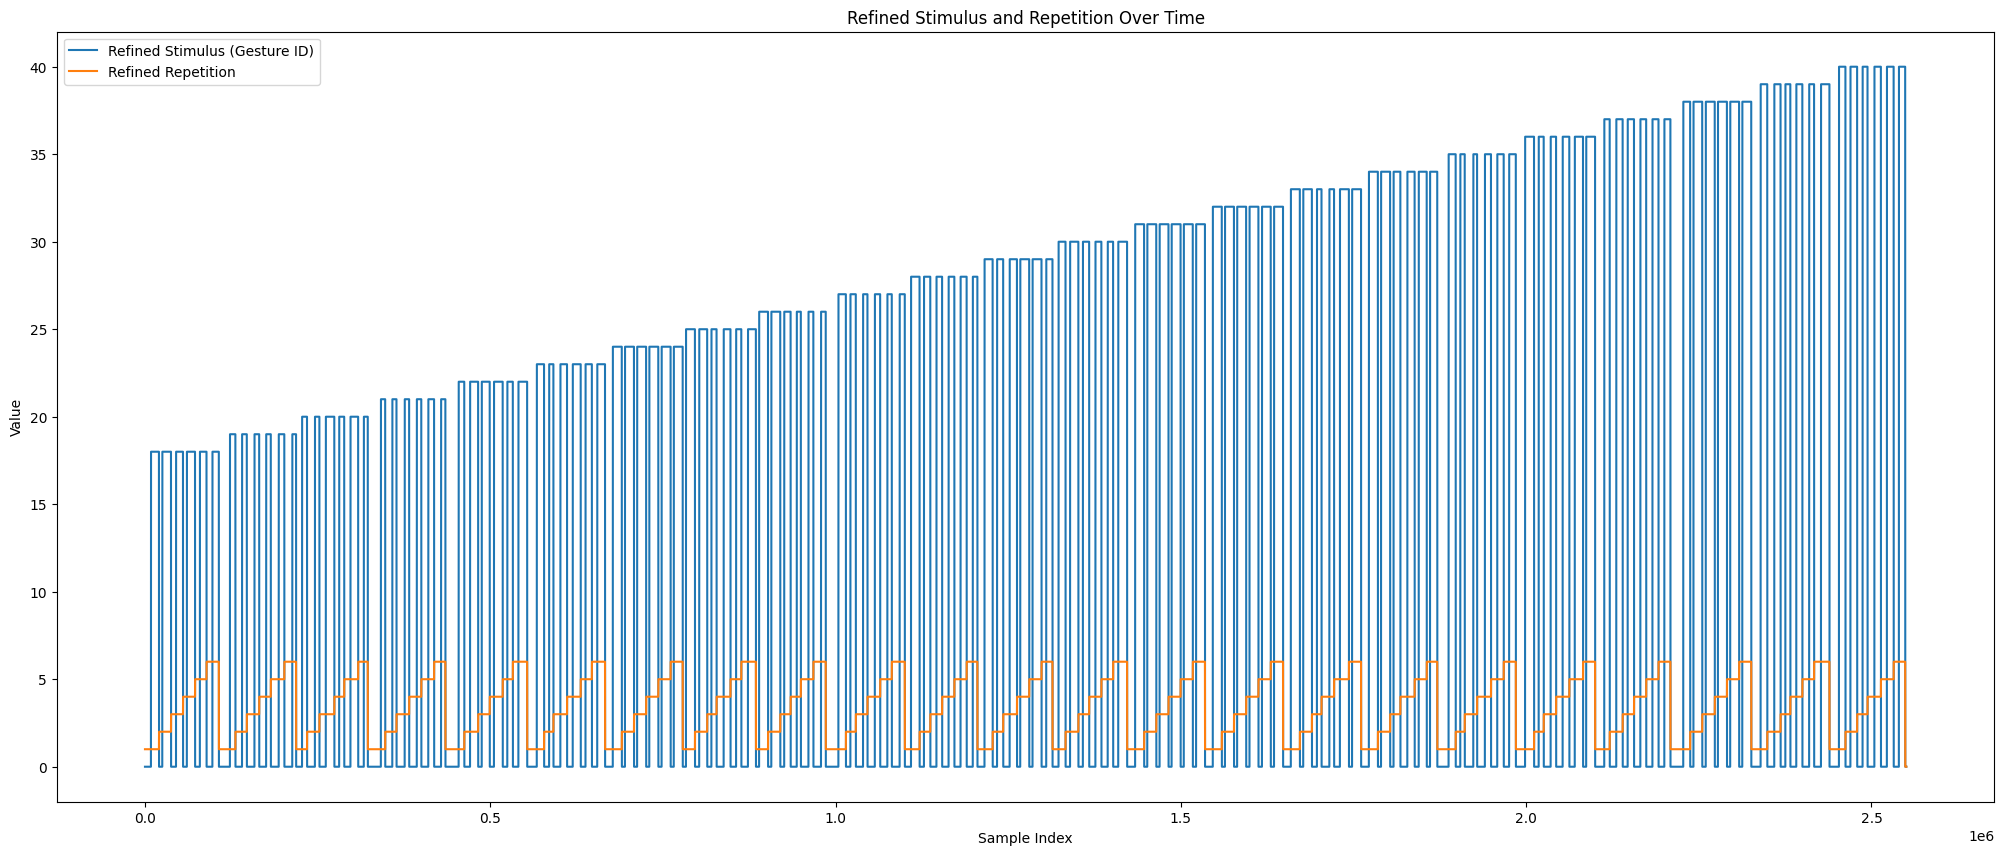

In [12]:
restimulus = mat['restimulus']
rerepetition = mat['rerepetition']

print(np.unique(restimulus))  # Unique refined gesture labels
print(np.unique(rerepetition))  # Unique refined repetition numbers

plt.figure(figsize=(25, 10))
plt.plot(restimulus, label='Refined Stimulus (Gesture ID)')
plt.plot(rerepetition, label='Refined Repetition')
plt.xlabel('Sample Index')
plt.ylabel('Value')
plt.title('Refined Stimulus and Repetition Over Time')
plt.legend()
plt.show()

In [ ]:
%cd ..

In [ ]:
import h5py
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path

# ------------------------------------------------------------------ #
# Config
# ------------------------------------------------------------------ #

HDF5_PATH    = Path("/vol/bitbucket/war124/data/ninapro_db2/ninapro_db2.hdf5")
SAMPLE_RATE  = 2000          # DB2 EMG is at 2kHz
WINDOW_SIZE  = 2000          # 1s at 2kHz
TRAIN_SPLIT  = "train"
TEST_SPLIT   = "test"
TASK_FILTER  = "ExerciseD"   # only Exercise 3 has force recordings

# N_FORCE will be determined dynamically from the data
# DB2 force sensor has 6 channels (finger force sensors)

# ------------------------------------------------------------------ #
# Helpers
# ------------------------------------------------------------------ #

def iter_force_runs(root, split):
    """
    Yield (run_group, subject_meta) for all runs matching split
    that belong to ExerciseD and contain force data.
    """
    for subj_id in root.keys():
        if not isinstance(root[subj_id], h5py.Group):
            continue
        subj_group = root[subj_id]
        subj_meta  = dict(subj_group.attrs)
        if subj_meta.get("inter_subject_split", "None") != split:
            continue
        for sess_id in subj_group.keys():
            if not isinstance(subj_group[sess_id], h5py.Group):
                continue
            sess_group = subj_group[sess_id]
            for run_key in sess_group.keys():
                if not isinstance(sess_group[run_key], h5py.Group):
                    continue
                run_group = sess_group[run_key]
                # Only ExerciseD runs with force data
                if run_group.attrs.get("task_name") != TASK_FILTER:
                    continue
                if "force" not in run_group:
                    continue
                yield run_group, subj_meta


def windowed_final_value(signal, window_size):
    """
    Extract the final value of each non-overlapping window.
    Returns (n_windows, C).
    """
    n_windows = len(signal) // window_size
    if n_windows == 0:
        return None
    truncated = signal[:n_windows * window_size]
    windows   = truncated.reshape(n_windows, window_size, signal.shape[1])
    return windows[:, -1, :]   # (n_windows, C)


def windowed_mean_velocity(signal, window_size):
    """
    Mean finite-difference velocity within each non-overlapping window.
    Returns (n_windows, C).
    """
    n_windows = len(signal) // window_size
    if n_windows == 0:
        return None
    truncated  = signal[:n_windows * window_size]
    windows    = truncated.reshape(n_windows, window_size, signal.shape[1])
    velocities = np.diff(windows, axis=1)   # (n_windows, W-1, C)
    return velocities.mean(axis=1)          # (n_windows, C)


def rmse(pred, target, axis=0):
    return np.sqrt(np.mean((pred - target) ** 2, axis=axis))


# ------------------------------------------------------------------ #
# Determine N_FORCE dynamically
# ------------------------------------------------------------------ #

with h5py.File(HDF5_PATH, "r") as f:
    root = f["ninapro_db2"]
    N_FORCE = None
    for run_group, _ in iter_force_runs(root, TRAIN_SPLIT):
        N_FORCE = run_group["force"].shape[1]
        break

if N_FORCE is None:
    raise RuntimeError(
        "No force runs found in training split. "
        "Check that ExerciseD runs with force data exist in the HDF5."
    )

print(f"Force channels detected: {N_FORCE}")

# ------------------------------------------------------------------ #
# Pass 1 — Training set statistics
# ------------------------------------------------------------------ #

print("=" * 60)
print("Pass 1: Computing training set statistics (ExerciseD only)")
print("=" * 60)

force_sum    = np.zeros(N_FORCE)
force_sq_sum = np.zeros(N_FORCE)
force_min    = np.full(N_FORCE,  np.inf)
force_max    = np.full(N_FORCE, -np.inf)

vel_sum      = np.zeros(N_FORCE)
vel_sq_sum   = np.zeros(N_FORCE)

run_lengths  = []
n_runs       = 0
n_samples    = 0

win_force_sum = np.zeros(N_FORCE)
win_vel_sum   = np.zeros(N_FORCE)
n_windows     = 0

with h5py.File(HDF5_PATH, "r") as f:
    root = f["ninapro_db2"]
    for run_group, _ in tqdm(iter_force_runs(root, TRAIN_SPLIT), desc="Train runs"):
        force = run_group["force"][:]   # (T, N_FORCE)
        T     = force.shape[0]

        force_sum    += force.sum(axis=0)
        force_sq_sum += (force ** 2).sum(axis=0)
        force_min     = np.minimum(force_min, force.min(axis=0))
        force_max     = np.maximum(force_max, force.max(axis=0))

        vels          = np.diff(force, axis=0)
        vel_sum      += vels.sum(axis=0)
        vel_sq_sum   += (vels ** 2).sum(axis=0)

        run_lengths.append(T)
        n_samples    += T
        n_runs       += 1

        fv = windowed_final_value(force, WINDOW_SIZE)
        mv = windowed_mean_velocity(force, WINDOW_SIZE)
        if fv is not None:
            win_force_sum += fv.sum(axis=0)
            win_vel_sum   += mv.sum(axis=0)
            n_windows     += len(fv)

force_mean    = force_sum    / n_samples
force_std     = np.sqrt(force_sq_sum / n_samples - force_mean ** 2)

vel_mean      = vel_sum      / (n_samples - n_runs)
vel_std       = np.sqrt(vel_sq_sum / (n_samples - n_runs) - vel_mean ** 2)

win_force_mean = win_force_sum / n_windows
win_vel_mean   = win_vel_sum   / n_windows

run_lengths    = np.array(run_lengths)

# ------------------------------------------------------------------ #
# Pass 2 — Test set baseline evaluation
# ------------------------------------------------------------------ #

print("\n" + "=" * 60)
print("Pass 2: Evaluating mean-prediction baseline on test set")
print("=" * 60)

test_rmse_per_ch     = np.zeros(N_FORCE)
test_vel_rmse_per_ch = np.zeros(N_FORCE)
n_test_runs          = 0

win_rmse_per_ch      = np.zeros(N_FORCE)
win_vel_rmse_per_ch  = np.zeros(N_FORCE)
n_test_windows       = 0

with h5py.File(HDF5_PATH, "r") as f:
    root = f["ninapro_db2"]
    for run_group, _ in tqdm(iter_force_runs(root, TEST_SPLIT), desc="Test runs"):
        force = run_group["force"][:]

        test_rmse_per_ch     += rmse(force_mean, force, axis=0)
        vels                  = np.diff(force, axis=0)
        test_vel_rmse_per_ch += rmse(vel_mean, vels, axis=0)
        n_test_runs          += 1

        fv = windowed_final_value(force, WINDOW_SIZE)
        mv = windowed_mean_velocity(force, WINDOW_SIZE)
        if fv is not None:
            win_rmse_per_ch     += rmse(win_force_mean, fv, axis=0)
            win_vel_rmse_per_ch += rmse(win_vel_mean,   mv, axis=0)
            n_test_windows      += len(fv)

test_rmse_per_ch     /= n_test_runs
test_vel_rmse_per_ch /= n_test_runs
win_rmse_per_ch      /= n_test_runs
win_vel_rmse_per_ch  /= n_test_runs

# ------------------------------------------------------------------ #
# Print summary
# ------------------------------------------------------------------ #

SEP  = "─" * 60
SEP2 = "═" * 60

print(f"\n{SEP2}")
print("  NINAPRO DB2 — FORCE AUDIT SUMMARY (ExerciseD only)")
print(SEP2)

print(f"\n{'Dataset Overview':}")
print(SEP)
print(f"  Task filter            : {TASK_FILTER}")
print(f"  Force channels         : {N_FORCE}")
print(f"  Training runs          : {n_runs}")
print(f"  Test runs              : {n_test_runs}")
print(f"  Total training samples : {n_samples:,}")
print(f"  Training windows (1s)  : {n_windows:,}")
print(f"  Run length — mean      : {run_lengths.mean():.1f} samples  "
      f"({run_lengths.mean()/SAMPLE_RATE:.2f}s)")
print(f"  Run length — min       : {run_lengths.min()} samples  "
      f"({run_lengths.min()/SAMPLE_RATE:.2f}s)")
print(f"  Run length — max       : {run_lengths.max()} samples  "
      f"({run_lengths.max()/SAMPLE_RATE:.2f}s)")
print(f"  Run length — std       : {run_lengths.std():.1f} samples")

print(f"\n{'Force Statistics (training set, sample-level)':}")
print(SEP)
print(f"  {'Channel':<10} {'Min':>8} {'Max':>8} {'Mean':>8} {'Std':>8} {'Range':>8}")
print(f"  {'─'*10} {'─'*8} {'─'*8} {'─'*8} {'─'*8} {'─'*8}")
for j in range(N_FORCE):
    print(f"  {j:<10} {force_min[j]:>8.3f} {force_max[j]:>8.3f} "
          f"{force_mean[j]:>8.3f} {force_std[j]:>8.3f} "
          f"{force_max[j]-force_min[j]:>8.3f}")
print(f"  {'─'*10} {'─'*8} {'─'*8} {'─'*8} {'─'*8} {'─'*8}")
print(f"  {'Mean':<10} {force_min.mean():>8.3f} {force_max.mean():>8.3f} "
      f"{force_mean.mean():>8.3f} {force_std.mean():>8.3f} "
      f"{(force_max-force_min).mean():>8.3f}")

print(f"\n{'Mean-Prediction Baseline RMSE (test set)':}")
print(SEP)
print(f"  {'Metric':<35} {'Mean RMSE':>10} {'Min Ch':>10} {'Max Ch':>10}")
print(f"  {'─'*35} {'─'*10} {'─'*10} {'─'*10}")
print(f"  {'Force — sample level':<35} "
      f"{test_rmse_per_ch.mean():>10.4f} "
      f"{test_rmse_per_ch.min():>10.4f} "
      f"{test_rmse_per_ch.max():>10.4f}")
print(f"  {'Force — window final frame (1s)':<35} "
      f"{win_rmse_per_ch.mean():>10.4f} "
      f"{win_rmse_per_ch.min():>10.4f} "
      f"{win_rmse_per_ch.max():>10.4f}")
print(f"  {'Velocity — sample level':<35} "
      f"{test_vel_rmse_per_ch.mean():>10.4f} "
      f"{test_vel_rmse_per_ch.min():>10.4f} "
      f"{test_vel_rmse_per_ch.max():>10.4f}")
print(f"  {'Velocity — window mean (1s)':<35} "
      f"{win_vel_rmse_per_ch.mean():>10.4f} "
      f"{win_vel_rmse_per_ch.min():>10.4f} "
      f"{win_vel_rmse_per_ch.max():>10.4f}")
print(SEP2)

# ------------------------------------------------------------------ #
# Visualisation
# ------------------------------------------------------------------ #

channels = np.arange(N_FORCE)
colors   = plt.cm.tab10(np.linspace(0, 1, N_FORCE))

fig = plt.figure(figsize=(16, 12))
fig.suptitle(
    f"NinaPro DB2 — Force Audit ({TASK_FILTER} only)",
    fontsize=14, fontweight="bold", y=0.98
)
gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.35)

# --- 1. Force range per channel ---
ax1 = fig.add_subplot(gs[0, 0])
ax1.bar(channels, force_max - force_min, color=colors, alpha=0.8,
        edgecolor="white", linewidth=0.5)
ax1.set_title("Force Range per Channel (training set)", fontweight="bold")
ax1.set_xlabel("Force channel")
ax1.set_ylabel("Range (% MVC)")
ax1.set_xticks(channels)
ax1.grid(axis="y", alpha=0.3)

# --- 2. Force mean ± std ---
ax2 = fig.add_subplot(gs[0, 1])
ax2.bar(channels, force_mean, color=colors, alpha=0.8,
        edgecolor="white", linewidth=0.5)
ax2.errorbar(channels, force_mean, yerr=force_std, fmt="none",
             ecolor="black", elinewidth=0.8, capsize=3)
ax2.axhline(0, color="black", linewidth=0.5, linestyle="--")
ax2.set_title("Force Mean ± Std (training set)", fontweight="bold")
ax2.set_xlabel("Force channel")
ax2.set_ylabel("Force (% MVC)")
ax2.set_xticks(channels)
ax2.grid(axis="y", alpha=0.3)

# --- 3. Baseline RMSE per channel ---
ax3 = fig.add_subplot(gs[1, 0])
w = 0.35
ax3.bar(channels - w/2, test_rmse_per_ch, width=w,
        label="Sample-level", color="steelblue", alpha=0.8)
ax3.bar(channels + w/2, win_rmse_per_ch,  width=w,
        label="Window final frame (1s)", color="coral", alpha=0.8)
ax3.axhline(test_rmse_per_ch.mean(), color="steelblue",
            linestyle="--", linewidth=1, alpha=0.7)
ax3.axhline(win_rmse_per_ch.mean(),  color="coral",
            linestyle="--", linewidth=1, alpha=0.7)
ax3.set_title("Mean-Prediction Baseline RMSE — Force (test set)", fontweight="bold")
ax3.set_xlabel("Force channel")
ax3.set_ylabel("RMSE (% MVC)")
ax3.set_xticks(channels)
ax3.legend(fontsize=8)
ax3.grid(axis="y", alpha=0.3)

# --- 4. Baseline RMSE per channel — velocity ---
ax4 = fig.add_subplot(gs[1, 1])
ax4.bar(channels - w/2, test_vel_rmse_per_ch, width=w,
        label="Sample-level", color="steelblue", alpha=0.8)
ax4.bar(channels + w/2, win_vel_rmse_per_ch,  width=w,
        label="Window mean (1s)", color="coral", alpha=0.8)
ax4.axhline(test_vel_rmse_per_ch.mean(), color="steelblue",
            linestyle="--", linewidth=1, alpha=0.7)
ax4.axhline(win_vel_rmse_per_ch.mean(),  color="coral",
            linestyle="--", linewidth=1, alpha=0.7)
ax4.set_title("Mean-Prediction Baseline RMSE — Force Velocity (test set)",
              fontweight="bold")
ax4.set_xlabel("Force channel")
ax4.set_ylabel("RMSE (% MVC / sample)")
ax4.set_xticks(channels)
ax4.legend(fontsize=8)
ax4.grid(axis="y", alpha=0.3)

# --- 5. Run length distribution ---
ax5 = fig.add_subplot(gs[2, 0])
ax5.hist(run_lengths / SAMPLE_RATE, bins=20, color="steelblue",
         alpha=0.8, edgecolor="white", linewidth=0.5)
ax5.axvline(run_lengths.mean() / SAMPLE_RATE, color="red",
            linestyle="--", linewidth=1.5,
            label=f"Mean = {run_lengths.mean()/SAMPLE_RATE:.2f}s")
ax5.set_title("Run Length Distribution (training set)", fontweight="bold")
ax5.set_xlabel("Duration (seconds)")
ax5.set_ylabel("Count")
ax5.legend(fontsize=8)
ax5.grid(axis="y", alpha=0.3)

# --- 6. Summary table ---
ax6 = fig.add_subplot(gs[2, 1])
ax6.axis("off")
table_data = [
    ["Metric",                          "Value"],
    ["Task filter",                     TASK_FILTER],
    ["Force channels",                  str(N_FORCE)],
    ["Training runs",                   str(n_runs)],
    ["Test runs",                       str(n_test_runs)],
    ["Training windows (1s)",           f"{n_windows:,}"],
    ["Mean run duration",               f"{run_lengths.mean()/SAMPLE_RATE:.2f}s"],
    ["Force RMSE baseline (sample)",    f"{test_rmse_per_ch.mean():.4f}"],
    ["Force RMSE baseline (window)",    f"{win_rmse_per_ch.mean():.4f}"],
    ["Vel RMSE baseline (sample)",      f"{test_vel_rmse_per_ch.mean():.4f}"],
    ["Vel RMSE baseline (window)",      f"{win_vel_rmse_per_ch.mean():.4f}"],
]
table = ax6.table(cellText=table_data[1:], colLabels=table_data[0],
                  loc="center", cellLoc="left")
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 1.4)
for (r, c), cell in table.get_celld().items():
    if r == 0:
        cell.set_facecolor("#2c3e50")
        cell.set_text_props(color="white", fontweight="bold")
    elif r % 2 == 0:
        cell.set_facecolor("#f2f2f2")
    cell.set_edgecolor("white")
ax6.set_title("Summary", fontweight="bold", pad=10)

figures_path = HDF5_PATH.parent / "audit_figures"
figures_path.mkdir(exist_ok=True)

plt.savefig(figures_path / "ninapro_db2_force_audit.pdf", bbox_inches="tight", dpi=150)
plt.savefig(figures_path / "ninapro_db2_force_audit.png", bbox_inches="tight", dpi=150)
print("\nFigure saved to figures/ninapro_db2_force_audit.pdf")